# Kinyarwanda Sentiment Classification: Data and Baseline

Tweets from the Kinyarwanda subset of AfriSenti (Muhammad et al., 2023), labelled positive, neutral or negative (CC BY 4.0). This notebook covers exploration, light cleaning and TF-IDF + Logistic Regression baselines.

## Setup

In [1]:
!pip install -q datasets scikit-learn pandas matplotlib seaborn

In [2]:
import re, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

## Data
The official train / validation / test split is used as provided. Recent versions of `datasets` no longer run the dataset's loading script, so the Parquet export is loaded directly. The splits hold 3,302 / 827 / 1,026 tweets, one fewer each than the 3,303 / 828 / 1,027 listed on the dataset card.

In [7]:
base = "hf://datasets/shmuhammad/AfriSenti-twitter-sentiment@refs%2Fconvert%2Fparquet/kin"
ds = load_dataset("parquet", data_files={
    "train":      f"{base}/train/0000.parquet",
    "validation": f"{base}/validation/0000.parquet",
    "test":       f"{base}/test/0000.parquet",
})
print(ds)

label_names = ds["train"].features["label"].names
print("Labels:", label_names)

DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 3302
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 827
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 1026
    })
})
Labels: ['positive', 'neutral', 'negative']


In [8]:
def to_df(split):
    df = ds[split].to_pandas()
    df["label_name"] = df["label"].map(lambda i: label_names[i])
    return df

train_df, val_df, test_df = to_df("train"), to_df("validation"), to_df("test")
for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:11s} {len(d):5d} tweets")
train_df.head(10)

train        3302 tweets
validation    827 tweets
test         1026 tweets


,tweet,label,label_name
0,@user @user @user @user @user @user @user Hhhh...,2,negative
1,"@user Amahano?! Ni impanuka, inkangu, inzara.....",2,negative
2,Ese umuntu aguhaye miliyoni 7 zidorali ngo ary...,2,negative
3,Ugira amagambo😏 kandi Ubwo wasanga nawe byagut...,2,negative
4,Ukuntu inama zose zikomeye zirikubera Mu Rwand...,2,negative
5,"Very sad! Umwana w'Ukwezi 1 koko...😠, Nyamara ...",2,negative
6,@user @user @user @user @user @user Azajya kwi...,2,negative
7,Ariko igitsina gore mukurahe imbaraga zituma m...,2,negative
8,"Iminsi yo yimurekere, iramubona! Bitinde biteb...",2,negative
9,@user @user @user @user @user @user @user @use...,2,negative


## Exploration

            train  validation  test
label_name                         
neutral      1257         315   393
negative     1146         287   355
positive      899         225   278

            train  validation   test
label_name                          
neutral     0.381       0.381  0.383
negative    0.347       0.347  0.346
positive    0.272       0.272  0.271


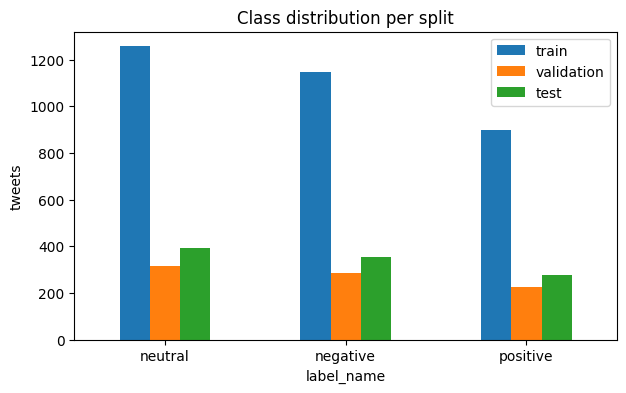

In [9]:
dist = pd.DataFrame({
    "train": train_df["label_name"].value_counts(),
    "validation": val_df["label_name"].value_counts(),
    "test": test_df["label_name"].value_counts(),
})
print(dist)
print()
print((dist / dist.sum()).round(3))

dist.plot(kind="bar", figsize=(7, 4), title="Class distribution per split")
plt.ylabel("tweets"); plt.xticks(rotation=0); plt.show()

       n_words  n_chars
count   3302.0   3302.0
mean      14.9    109.6
std        5.7     46.3
min        4.0     23.0
25%       10.0     74.0
50%       15.0    109.0
75%       19.0    139.0
max       69.0    458.0


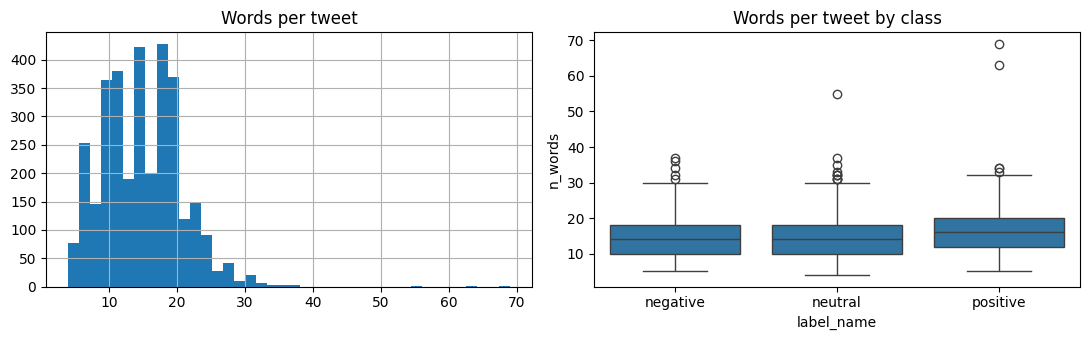

In [10]:
train_df["n_words"] = train_df["tweet"].str.split().str.len()
train_df["n_chars"] = train_df["tweet"].str.len()
print(train_df[["n_words", "n_chars"]].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train_df["n_words"].hist(bins=40, ax=ax[0]); ax[0].set_title("Words per tweet")
sns.boxplot(data=train_df, x="label_name", y="n_words", ax=ax[1]); ax[1].set_title("Words per tweet by class")
plt.tight_layout(); plt.show()

In [11]:
for _, r in train_df.sample(30, random_state=1).iterrows():
    print(f"[{r['label_name']:>8}] {r['tweet']}")

[negative] Kubeshya bikaryoha kubi 😭😭😭😭😭😭😭🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣 Ni nko gusambana🤣🤣🤣🤣🤣🤣 https://t.co/HHmi0e53co
[negative] @user Ubwose iyo zabarizawe kontumva twari nokubura abanyeshuri
[ neutral] Nyakubahwa Perezida wa Repubulika y'u Rwanda Paul KAGAME yafashe urukingo rw'icyorezo cya COVID-19. https://t.co/iraG4yTFPD
[positive] Turashima cyane ubufasha leta yatugeneye I #Rubavu, Akawunga, umuceli n’ibishyimbo byatugezeho. Biradufasha guhangana na Covid 19 turi mu ngo zacu. #sindohoka #NtaKudohoka https://t.co/zapLJ6L3uO
[negative] @user @user My a good fool advice buy harlot.indaya nisawa izaguha byose umugera na sida
[ neutral] Fred Robinson Mugisha uzwi nka Element, umaze kwamamara mu gutunganya umuziki, araba ari mu kiganiro #Amahumbezi uyu munsi 15h00. Ntimucikwe. https://t.co/gagLFSF8jl
[positive] @user @user @user Ewana ni byose kbs. @user yacu Ku isonga mu gihugu hose muguhindura ubuzima bw'abanyarwanda, abaturarwanda ndetse n'abanyamahanga.@user hejuru cyane🙏🙏🙏🙏🤝🤝🤝 https://t.co/3UD87VmL

In [12]:
print("Empty tweets:", (train_df["tweet"].str.strip() == "").sum())
print("Duplicates in train:", train_df["tweet"].duplicated().sum())

conflict = train_df.groupby("tweet")["label"].nunique()
print("Tweets with conflicting labels:", (conflict > 1).sum())

leak = set(test_df["tweet"]) & set(train_df["tweet"])
print("Test tweets also in train:", len(leak))

emoji = r"[\U0001F300-\U0001FAFF\u2600-\u27BF]"
print("Contain @user:", train_df["tweet"].str.contains("@user").mean().round(3))
print("Contain #hashtag:", train_df["tweet"].str.contains("#").mean().round(3))
print("Contain emoji/symbols:", train_df["tweet"].apply(lambda s: bool(re.search(emoji, s))).mean().round(3))

Empty tweets: 0
Duplicates in train: 43
Tweets with conflicting labels: 9
Test tweets also in train: 29
Contain @user: 0.705
Contain #hashtag: 0.151
Contain emoji/symbols: 0.324


### Observations
- Neutral is the largest class (38%), then negative (35%) and positive (27%). Proportions are almost identical across the three splits, so the imbalance is mild.
- Tweets are short: about 15 words (110 characters) on average, from 4 to 69 words.
- Most are replies. 70% contain `@user`, 15% a hashtag and 32% an emoji or symbol, and many start with long runs of `@user`.
- Language is informal: some English is mixed in ("Very sad!", "bro", "serious"), spellings are shortened ("kbs", "kbx") and words are often run together.
- `t.co` links are still present in many tweets, although the dataset card says URLs were removed.
- In the sample, neutral mixes announcements and news-style posts with conversational replies and questions, so it looks less cohesive than positive or negative.
- Duplicates and leakage are small but present: 43 duplicate tweets in train, 9 with conflicting labels, and 29 test tweets (2.8%) that also appear in train.

## Cleaning
Cleaning is kept minimal: `@user` is dropped, text is lowercased and whitespace is collapsed. Emojis, punctuation, hashtags and links are left in place, since emojis in particular often carry sentiment. Lowercasing also changes the leftover links, which adds some noise; stripping them is a possible later change.

In [13]:
def clean(text: str) -> str:
    text = re.sub(r"@user", " ", text)
    text = text.lower()
    return re.sub(r"\s+", " ", text).strip()

for d in (train_df, val_df, test_df):
    d["clean"] = d["tweet"].apply(clean)

print(train_df[["tweet", "clean"]].sample(5, random_state=3).to_string())

                                                                                                                                                                                            tweet                                                                                                                                                                                        clean
414                                                             Nuko murugwiro inama iraterana Bazana igitabo cya lockdown habura numwe ukibumbura imana iturinde imyanzuro iduheza muburiri🤒😭😭😭😭                                                            nuko murugwiro inama iraterana bazana igitabo cya lockdown habura numwe ukibumbura imana iturinde imyanzuro iduheza muburiri🤒😭😭😭😭
1162                                                                                        #BnBSports Ni bande ubona ku ifoto? Aba bagabo, ubibukira kuki? #SimplySports https://t.co/xAHO17PAkg                                         

## Baseline: TF-IDF + Logistic Regression
A fast model with no word order and no pretrained knowledge, which makes it a floor for the later models. Macro-F1 is the main metric because it weights the three classes equally. Class weights are balanced to offset the mild imbalance.

In [14]:
def evaluate(name, y_true, y_pred, store):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    store[name] = {"accuracy": round(acc, 4), "macro_precision": round(p, 4),
                   "macro_recall": round(r, 4), "macro_f1": round(f1, 4)}
    print(f"{name}: acc={acc:.3f}  macro-P={p:.3f}  macro-R={r:.3f}  macro-F1={f1:.3f}")

results = {}
X_train, y_train = train_df["clean"], train_df["label"]
X_val,   y_val   = val_df["clean"],   val_df["label"]
X_test,  y_test  = test_df["clean"],  test_df["label"]

In [15]:
# Word-level TF-IDF (unigrams + bigrams); vectorizer fitted on train only
word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = word_vec.fit_transform(X_train)
Xva, Xte = word_vec.transform(X_val), word_vec.transform(X_test)
print("Vocabulary size:", len(word_vec.vocabulary_))

clf_word = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
clf_word.fit(Xtr, y_train)

evaluate("tfidf_word_LR (val)",  y_val,  clf_word.predict(Xva), results)
evaluate("tfidf_word_LR (test)", y_test, clf_word.predict(Xte), results)

Vocabulary size: 6506
tfidf_word_LR (val): acc=0.577  macro-P=0.578  macro-R=0.581  macro-F1=0.579
tfidf_word_LR (test): acc=0.562  macro-P=0.568  macro-R=0.567  macro-F1=0.567


In [16]:
# Character n-grams, since Kinyarwanda words carry many prefixes and suffixes
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
Ctr = char_vec.fit_transform(X_train)
Cva, Cte = char_vec.transform(X_val), char_vec.transform(X_test)
print("Character n-gram features:", len(char_vec.vocabulary_))

clf_char = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
clf_char.fit(Ctr, y_train)

evaluate("tfidf_char_LR (val)",  y_val,  clf_char.predict(Cva), results)
evaluate("tfidf_char_LR (test)", y_test, clf_char.predict(Cte), results)

Character n-gram features: 40894
tfidf_char_LR (val): acc=0.641  macro-P=0.641  macro-R=0.645  macro-F1=0.642
tfidf_char_LR (test): acc=0.595  macro-P=0.597  macro-R=0.604  macro-F1=0.597


              precision    recall  f1-score   support

    positive       0.62      0.60      0.61       278
     neutral       0.53      0.50      0.51       393
    negative       0.55      0.60      0.58       355

    accuracy                           0.56      1026
   macro avg       0.57      0.57      0.57      1026
weighted avg       0.56      0.56      0.56      1026



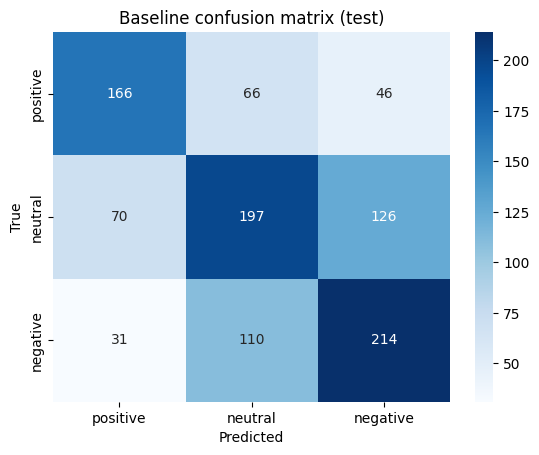

In [17]:
# Detailed report for the word-level model
pred_test = clf_word.predict(Xte)
print(classification_report(y_test, pred_test, target_names=label_names, zero_division=0))

cm = confusion_matrix(y_test, pred_test)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Baseline confusion matrix (test)"); plt.show()

In [18]:
# Highest-weighted words per class
feat_names = np.array(word_vec.get_feature_names_out())
for i, name in enumerate(label_names):
    top = np.argsort(clf_word.coef_[i])[-12:][::-1]
    print(f"{name:>8}: {', '.join(feat_names[top])}")

positive: mwiza, cyane, neza, amahoro, nziza, ibyiza, imana, rwanda, humura, uwiteka, kandi, byiza
 neutral: iki, na, ya, ese, kuri, se, gukora, ikiganiro, wa, iyi, harya, nari
negative: ngo, nabi, ari, cg, ubusa, ibaze, umunwa, ntacyo, ko, mubi, birababaje, umukobwa


### Observations
- Character n-grams beat word n-grams on both splits (macro-F1 0.642 vs 0.579 on validation, 0.597 vs 0.567 on test), in line with Kinyarwanda words carrying many affixes. The gain is modest, and the validation advantage shrinks on test (a gap of 0.045 for the character model against 0.012 for the word model).
- For the word-level model, F1 is highest for positive (0.61), then negative (0.58) and neutral (0.51).
- Neutral is the weak class. Of the 449 misclassified test tweets, 372 (83%) involve neutral, while positive and negative are rarely swapped (46 and 31 cases).
- The top words for positive and negative are mostly sentiment-bearing ("mwiza", "neza", "nziza" against "nabi", "mubi", "birababaje"). The neutral list is mostly function and question words ("iki", "ese", "se", "harya"), so the model has no distinctive vocabulary for that class.
- "rwanda" and "imana" appear among the positive cues, which look more topical than sentimental.

## Saving results and errors

In [19]:
with open("baseline_results.json", "w") as f:
    json.dump(results, f, indent=2)
print(pd.DataFrame(results).T)

err = test_df.copy()
err["pred"] = [label_names[i] for i in pred_test]
err = err[err["pred"] != err["label_name"]][["tweet", "label_name", "pred"]]
err["error_type"] = ""  # to be filled in during error analysis
err.to_csv("baseline_errors.csv", index=False)
print(f"\n{len(err)} misclassified test tweets saved to baseline_errors.csv")

                      accuracy  macro_precision  macro_recall  macro_f1
tfidf_word_LR (val)     0.5768           0.5781        0.5809    0.5792
tfidf_word_LR (test)    0.5624           0.5681        0.5671    0.5670
tfidf_char_LR (val)     0.6409           0.6412        0.6452    0.6417
tfidf_char_LR (test)    0.5945           0.5966        0.6038    0.5972

449 misclassified test tweets saved to baseline_errors.csv


The saved errors are from the word-level model (449 of 1,026 test tweets, 44%).